# Emissões de CO₂ nas cadeias produtivas brasileiras

Este notebook estima as emissões da produção brasileira em 2015 e apresenta duas atribuições do mesmo total: **por atividade emissora** e **por atividade da demanda final**. A exposição desenvolve os objetos da contabilidade ambiental, relaciona-os às metodologias de Sanguinet e Azzoni (2024) e Marques et al. (2012) e aplica as contas à matriz de insumo-produto brasileira.


## 1. Objetivo, dados e abrangência

![Figura de motivação](apresentacao_exploratoria/motivação.png)

A produção de um bem mobiliza atividades ao longo de uma cadeia. As emissões podem ser identificadas pelo setor em que ocorrem ou atribuídas à demanda final atendida por essa cadeia. As perguntas desta análise são:

1. **Onde as emissões ocorrem?** Quanto CO₂ é gerado em cada atividade produtiva?
2. **Qual demanda final mobiliza essas emissões?** Quanto CO₂ é gerado na cadeia nacional para atender à demanda final por produtos de cada atividade?

### Fontes e preparação dos dados

A base econômica é a **MIP nacional do IBGE de 2015**, com **67 atividades e 127 produtos**. As intensidades de emissão provêm da Tabela 2 de Sanguinet e Azzoni. A comparação das atribuições utiliza também Marques et al.:

- [Sanguinet e Azzoni (2024), *Carbon emissions drivers in Brazilian regional production chains: Value-added and consumption-based approaches*](references/sanguinet_azzoni_2024/carbon_emissions_drivers_brazilian_regional_production_chains.pdf), seção 2.1, p. 2, equações 1 e 3a–3b; Tabela 2. [DOI](https://doi.org/10.1016/j.rspp.2024.100015).
- [Marques et al. (2012), *Income-based environmental responsibility*](references/marques_et_al_2012/income_based_environmental_responsibility.pdf), seção 6.1, p. 62, equações 1 e 2. [DOI](https://doi.org/10.1016/j.ecolecon.2012.09.010).

O vetor de intensidades para 2015 é estimado por interpolação linear dos coeficientes publicados para 2011 e 2018:

$$\varphi=\varphi_{2015}=\varphi_{2011}+\frac47(\varphi_{2018}-\varphi_{2011}).$$

Esses coeficientes são aplicados aos valores monetários de 2015 sem ajuste adicional de preços. A compatibilidade das bases de preços é, portanto, uma limitação da estimativa. As quantidades de emissões calculadas representam esse cenário metodológico, e não um inventário observado em 2015.

### Fronteira da análise

São contabilizadas as emissões **geradas no Brasil** para atender à demanda final por produtos nacionais, incluindo exportações. As emissões ocorridas no exterior na produção dos bens importados ficam fora dessa fronteira. A atribuição à demanda final corresponde, assim, à parcela doméstica das cadeias atendidas pela produção brasileira; não constitui uma pegada completa do consumo dos residentes.

A aplicação utiliza relações contábeis dos artigos em uma MIP nacional. Seu escopo é a comparação setorial dessas duas atribuições em 2015; as análises multirregionais e temporais dos artigos e a atribuição pela renda não são estimadas aqui.


## 2. Notação e quadro de objetos

**Produção bruta** inclui a produção destinada a usos intermediários e finais. **Demanda final** compreende consumo, investimento, variação de estoques e exportações, excluindo as compras intermediárias. Neste recorte, ambos os conceitos se referem à produção de origem nacional.

### Convenções e unidades

- **Vetores:** letras minúsculas, como $x$, $y$, $c$, $u$ e $\varphi$, sempre em formato coluna. O subscrito identifica um elemento: $x_i$ é a produção da atividade $i$.
- **Matrizes e índices:** letras maiúsculas, como $A$, $D$, $L$, $C$ e $F$. O primeiro índice identifica a linha; o segundo, a coluna. Em $C_{ij}$ e $F_{ij}$, $i$ identifica o emissor e $j$ a atividade da demanda final. O índice $p$ identifica produtos.
- **Diagonalização:** $\hat x=\operatorname{diag}(x)$ coloca os elementos de $x$ na diagonal e zeros nas demais posições. Para as intensidades, $\Phi=\operatorname{diag}(\varphi)=\hat\varphi$.
- **Transposição:** $M^\top$ troca linhas por colunas; $(M^\top)_{ji}=M_{ij}$. Se $x$ tem dimensão $67\times1$, $x^\top$ tem dimensão $1\times67$.
- **Potência e inversa:** $A^2=AA$; $M^{-1}$ é a inversa matricial, quando existe. Para $x_i\ne0$, $\hat x^{-1}=\operatorname{diag}(1/x_i)$.
- **Escrita LaTeX:** `^` introduz um sobrescrito, como em `A^2` ou `F^\top`; `\hat{x}` produz o chapéu que indica diagonalização.
- **Identidade e vetor de uns:** $I$ é a matriz identidade, com uns na diagonal e zeros fora dela; $\mathbf1$ é um vetor-coluna de uns, com dimensão compatível com a operação. Para as atividades desta análise, sua dimensão é $67\times1$.
- **Produtos e somatórios:** a justaposição indica produto matricial. Em $\sum_jF_{ij}$, soma-se cada linha, preservando $i$; em $\sum_iF_{ij}$, soma-se cada coluna, preservando $j$. $F\mathbf1$ e $F^\top\mathbf1$ organizam esses resultados como vetores-coluna. $\mathbf1^\top F$ organiza os totais das colunas como vetor-linha.

Em duas dimensões, essas convenções assumem a forma:

$$x=\begin{bmatrix}x_1\\x_2\end{bmatrix},\quad x^\top=\begin{bmatrix}x_1&x_2\end{bmatrix},\quad
\hat x=\begin{bmatrix}x_1&0\\0&x_2\end{bmatrix},\quad \mathbf1=\begin{bmatrix}1\\1\end{bmatrix}.$$

$$F\mathbf1=\begin{bmatrix}F_{11}+F_{12}\\F_{21}+F_{22}\end{bmatrix},\qquad
F^\top\mathbf1=\begin{bmatrix}F_{11}+F_{21}\\F_{12}+F_{22}\end{bmatrix}.$$

Os valores monetários estão em **milhões de reais** e as emissões em **Gg de CO₂**: 1 Gg = 1.000 toneladas. A massa contabilizada é a do dióxido de carbono, distinta da massa de carbono elementar.

### Entradas: MIP e coeficientes de emissão

| Objeto | Símbolo | Dimensão | Interpretação e unidade | Fonte |
|---|---|---|---|---|
| Produção bruta | $x$ | 67 × 1 | Produção por atividade; milhões de reais | IBGE, `'01'!H134:BV134` |
| Demanda final por produto | $f$ | 127 × 1 | Usos finais de produtos nacionais, incluindo exportações; milhões de reais | IBGE, `'03'!BZ6:BZ132` |
| Participação na produção | $D$ | 67 × 127 | Participação de cada atividade na produção de cada produto; adimensional | IBGE, `'13'!C6:DY72` |
| Inversa de Leontief | $L$ | 67 × 67 | Produção de $i$ por unidade de demanda final de $j$; razão monetária adimensional | IBGE, `'15'!C6:BQ72` |
| Intensidade direta estimada | $\varphi$ | 67 × 1 | Emissão no próprio setor por unidade de sua produção; Gg CO₂/milhão de reais de produção | Sanguinet e Azzoni, Tabela 2; interpolação descrita na seção 1 |

### Saídas e objetos calculados

As definições deste quadro são desenvolvidas nas seções 3 e 4.

| Objeto | Símbolo | Dimensão | Interpretação e unidade | Fórmula e identidades |
|---|---|---|---|---|
| Demanda final por atividade | $y$ | 67 × 1 | Demanda convertida de produtos para atividades; milhões de reais | $y=Df$; $x=Ly$ |
| Intensidades diagonalizadas | $\Phi$ | 67 × 67 | Intensidades na diagonal; Gg CO₂/milhão de reais de produção | $\Phi=\operatorname{diag}(\varphi)$ |
| Coeficientes de emissões | $C$ | 67 × 67 | Emissão em $i$ por unidade de demanda final de $j$; Gg CO₂/milhão de reais de demanda final | $C=\Phi L$; $C_{ij}=\varphi_iL_{ij}$ |
| Emissões por origem e destino final | $F$ | 67 × 67 | Quantidade emitida em $i$ atribuída à demanda final de $j$; Gg CO₂ | $F=C\hat y$; $F_{ij}=C_{ij}y_j$ |
| Emissões por setor emissor | $c$ | 67 × 1 | Soma de cada linha de $F$, preservando o emissor $i$; Gg CO₂ | $c=F\mathbf1=Cy=\Phi Ly=\Phi x$; $c_i=\sum_jF_{ij}=\varphi_i x_i$ |
| Emissões por demanda final | $u$ | 67 × 1 | Soma de cada coluna de $F$, preservando o destino $j$; Gg CO₂ | $u=F^\top\mathbf1=\hat yL^\top\varphi$; $u_j=\sum_iF_{ij}=y_j\sum_i\varphi_iL_{ij}$ |


## 3. Demanda final e produção

A matriz $D$ converte a demanda final por produto em demanda final por atividade:

$$y=Df.$$

Na matriz de transações intermediárias, $Z_{ij}$ registra a venda do setor $i$ ao setor $j$. Dividir cada coluna pela produção do comprador fornece os coeficientes técnicos:

$$A=Z\hat x^{-1},\qquad A_{ij}=\frac{Z_{ij}}{x_j}.$$

O balanço entre produção, usos intermediários e demanda final é:

$$x=Ax+y\quad\Longrightarrow\quad x=(I-A)^{-1}y=Ly.$$

A inversa de Leontief $L$ reúne os requisitos produtivos diretos e indiretos. Quando o raio espectral de $A$ é menor que 1, a série converge e:

$$L=I+A+A^2+\cdots,\qquad x=y+Ay+A^2y+\cdots.$$

O termo $y$ representa a produção para uso final; $Ay$, os insumos dessa produção; $A^2y$, os insumos dos fornecedores, e assim sucessivamente. Sob coeficientes fixos, uma mudança $\Delta y$ requer $\Delta x=L\Delta y$.

A implementação utiliza $L$ fornecida pela Tabela 15 do IBGE e confere a identidade $Ly=x$ com a produção informada na MIP.


## 4. Contabilidade das emissões

### 4.1. Intensidades e quantidades

A intensidade direta $\varphi_i$ relaciona emissões à produção do setor emissor. Sua organização diagonal permite calcular os coeficientes de emissões por demanda final:

$$\Phi=\operatorname{diag}(\varphi),\qquad C=\Phi L,\qquad C_{ij}=\varphi_iL_{ij}.$$

$C_{ij}$ mede a emissão no setor $i$ por **1 milhão de reais de demanda final de $j$**, considerando os encadeamentos produtivos. A quantidade correspondente à demanda efetiva $y_j$ é:

$$\boxed{F=C\hat y,\qquad F_{ij}=C_{ij}y_j.}$$

Assim, cada coluna de $C$ recebe o valor monetário da demanda final daquele destino. A unidade resultante é:

$$\frac{\mathrm{Gg\ CO_2}}{\mathrm{R\$\ milhão\ de\ demanda\ final}}
\times\mathrm{R\$\ milhões\ de\ demanda\ final}=\mathrm{Gg\ CO_2}.$$

$F$ registra uma **atribuição contábil** das emissões entre origens e destinos finais. Seus elementos não são transações diretas entre setores nem transferências físicas de CO₂. A diagonal $F_{ii}$ atribui à demanda final de $i$ as emissões ocorridas no próprio setor, incluindo retornos da cadeia representados em $L_{ii}$.

### 4.2. Somas de coeficientes: colunas e linhas de $C$

**Soma de cada coluna.** Mantendo a demanda final $j$, a soma sobre os emissores fornece sua intensidade total de emissões:

$$\sum_iC_{ij}=\sum_i\varphi_iL_{ij}.$$

Todos os termos têm a mesma base: 1 milhão de reais de demanda final de $j$. O resultado, em Gg CO₂/milhão de reais, reúne as emissões do próprio setor e de seus fornecedores diretos e indiretos. A produção desses fornecedores é determinada por $L$.

**Soma de cada linha.** Mantendo o emissor $i$, a soma sobre os destinos é:

$$\sum_jC_{ij}=\varphi_i\sum_jL_{ij}.$$

Cada termo se refere à demanda final de uma atividade diferente. A soma expressa a resposta do emissor a uma variação monetária igual em todos os destinos. Se $q$ é o valor aplicado à demanda final de cada atividade, então:

$$\Delta y=q\mathbf1,\qquad \Delta c_i=q\sum_jC_{ij}.$$

Para $q=\text{1 milhão de reais}$, $\Delta c_i$ em Gg CO₂ tem o mesmo valor numérico que a soma da linha de $C$. A expansão total da demanda é **67 milhões de reais** e a produção varia segundo $L\Delta y$. Esse cenário fixa a demanda final de cada atividade, e não sua produção bruta.

Uma intensidade por unidade de **demanda final agregada** exige definir a composição dessa demanda. Para participações $s_j$ cuja soma é 1, a intensidade no emissor $i$ é $\sum_jC_{ij}s_j$. Com repartição igual entre as 67 atividades, ela é a média da linha, $\frac1{67}\sum_jC_{ij}$. Portanto, a soma da linha é válida para o cenário de demandas iguais; interpretá-la como intensidade por milhão agregado, sem especificar a composição, confunde duas bases monetárias distintas.

### 4.3. Somas de quantidades: linhas e colunas de $F$

**Soma de cada linha: atribuição por emissor.** Somar os destinos finais preserva o setor onde ocorre a emissão:

$$\boxed{c_i=\sum_jF_{ij}=\sum_jC_{ij}y_j=\varphi_i\sum_jL_{ij}y_j=\varphi_i x_i.}$$

$$c=F\mathbf1=Cy=\Phi Ly=\Phi x.$$

$c_i$ é a quantidade emitida no próprio setor para realizar toda a sua produção. A expressão $\Phi x$ parte da produção informada na MIP; $\Phi Ly$ parte dos requisitos da demanda final. A identidade $x=Ly$ torna as duas contas equivalentes.

**Soma de cada coluna: atribuição por demanda final.** Somar os emissores preserva o destino final:

$$\boxed{u_j=\sum_iF_{ij}=y_j\sum_iC_{ij},\qquad u=F^\top\mathbf1=\hat yL^\top\varphi.}$$

$u_j$ reúne as emissões de toda a cadeia nacional atribuídas à demanda final de $j$. Como $y_j$ é comum aos elementos da coluna, ele pode ser colocado fora do somatório. A ponderação ocorre na passagem de $C$ a $F$; a soma de $F$ já resulta em Gg CO₂. Uma nova multiplicação por $y_j$ produziria a unidade Gg CO₂ × milhões de reais, incompatível com uma quantidade de emissões.

| Operação | Índice preservado | Resultado e base de interpretação |
|---|---|---|
| Coluna de $C$: $\sum_iC_{ij}$ | Destino $j$ | Intensidade da cadeia por milhão de reais de demanda final de $j$ |
| Linha de $C$: $\sum_jC_{ij}$ | Emissor $i$ | Coeficiente de resposta em $i$ por milhão de reais aplicado à demanda final **de cada atividade** |
| Linha de $F$: $\sum_jF_{ij}$ | Emissor $i$ | Quantidade emitida em $i$ para todos os destinos; $c_i$, em Gg CO₂ |
| Coluna de $F$: $\sum_iF_{ij}$ | Destino $j$ | Quantidade emitida na cadeia para atender a $y_j$; $u_j$, em Gg CO₂ |

### 4.4. Encadeamentos, emissões diretas e conservação

Expandir a produção requerida explicita as etapas que geram as emissões:

$$c=\Phi Ly=\Phi y+\Phi Ay+\Phi A^2y+\cdots.$$

A emissão é **direta em relação ao setor que a gera** e pode ser **indireta em relação à demanda final atendida**. A emissão do cimento utilizado na construção, por exemplo, ocorre diretamente no cimento e integra indiretamente a cadeia da demanda final de construção. No vetor $c$, ela permanece na posição do cimento; no vetor $u$, a parcela associada à construção é atribuída a esse destino.

As duas atribuições repartem o mesmo total estimado:

$$\mathbf1^\top c=\sum_i\sum_jF_{ij}=\mathbf1^\top u.$$

Somar os totais de $c$ e $u$ contaria as mesmas emissões duas vezes. Setorialmente, $c_i$ e $u_i$ podem diferir porque o primeiro se refere à produção bruta $x_i$, enquanto o segundo se refere à demanda final $y_i$. Por essa razão, $u_i-c_i$ não mede as emissões dos fornecedores de toda a produção de $i$.


## 5. Correspondência com os artigos

### 5.1. Sanguinet e Azzoni: equação 3a

A equação 3a, na seção 2.1 do artigo, relaciona intensidades, requisitos produtivos e demanda final:

$$C_t=\hat\varphi(I-A)^{-1}Y=\hat\varphi L\vartheta\,y_{\mathrm{total}}.$$

O vetor $\vartheta$ contém as participações na demanda final, com $Y=\vartheta y_{\mathrm{total}}$. O símbolo $y_{\mathrm{total}}$ representa aqui o escalar denominado $y$ no artigo. A correspondência é:

| Sanguinet e Azzoni | Neste notebook | Significado |
|---|---|---|
| $Y$ | $y$ | Vetor de demanda final por atividade |
| $\hat\varphi$ | $\Phi$ | Intensidades diagonalizadas |
| $C_t$ | $c$ | Vetor de quantidades emitidas por setor |

Com intensidade diagonal e demanda vetorial, a expressão corresponde a $c=\Phi Ly$. A referência do artigo a emissões diretas e indiretas diz respeito aos requisitos da cadeia explicitados na seção 4.4. A posição no vetor resultante identifica o emissor.

Os símbolos têm funções distintas entre os textos: o $C_t$ do artigo é um vetor de quantidades; o $C$ deste notebook é uma matriz de coeficientes. Da mesma forma, o $F_t$ da abordagem de oferta do artigo não corresponde à matriz $F$ de origem e destino final definida aqui.

### 5.2. Marques et al.: equação 1

Marques parte do vetor $e$ de emissões diretas. Usando $\top$ para a transposta, indicada por uma aspa no artigo:

$$u^\top=(e^\top\hat x^{-1})(I-Z\hat x^{-1})^{-1}\hat y.$$

As duas ocorrências de $\hat x^{-1}$ normalizam objetos diferentes:

- $e^\top\hat x^{-1}=\varphi^\top$ converte quantidades de emissões em intensidades por produção.
- $Z\hat x^{-1}=A$ converte transações intermediárias em coeficientes técnicos por produção do comprador.

Na aplicação nacional, $e=c$ e as entradas já fornecem $\varphi$ e $L$. Substituindo essas definições e usando $\varphi^\top=\mathbf1^\top\Phi$:

$$u^\top=\varphi^\top L\hat y=\mathbf1^\top\Phi L\hat y=\mathbf1^\top F.$$

Portanto, a equação 1 fornece a soma de cada coluna de $F$, conforme a seção 4.3. Seu resultado é a quantidade atribuída à demanda final; $e_i=c_i$ corresponde ao total da linha do emissor, para dados e fronteiras consistentes.

### 5.3. Atribuição pela renda e inversa de Ghosh

A abordagem pela renda acompanha relações a jusante e atribui emissões aos fornecedores de insumos primários remunerados pela atividade produtiva. Na notação da equação 2 de Marques, $v$ é o vetor **monetário de valor adicionado**. Definindo os coeficientes de alocação e a inversa de Ghosh:

$$B=\hat x^{-1}Z,\qquad G=(I-B)^{-1},$$

a expressão é:

$$d=\hat vG\hat x^{-1}e=\hat vG\varphi.$$

Essa terceira atribuição requer objetos diferentes dos usados na conta por produção $c=\Phi x$. A abordagem de oferta/renda também é tratada na equação 3b de Sanguinet e Azzoni, com notação própria. Este notebook calcula $c$ e $u$; a estimação de $d$ e de $G$ permanece fora do escopo definido na seção 1.


## 6. Exemplo numérico integrado

Considere uma economia hipotética com **cimento** e **construção**, nessa ordem. O cimento não utiliza insumos intermediários; a construção utiliza 0,5 real de cimento por 1 real de produção. Não há outros insumos intermediários. Os valores são didáticos, sem correspondência com estimativas da MIP brasileira.

### Produção e demanda final

$$A=\begin{bmatrix}0&0{,}5\\0&0\end{bmatrix},\qquad
L=(I-A)^{-1}=\begin{bmatrix}1&0{,}5\\0&1\end{bmatrix}.$$

Para a demanda final $y=(100,200)^\top$, em milhões de reais:

$$x=Ly=\begin{bmatrix}200\\200\end{bmatrix}.$$

O cimento produz 100 para sua demanda final e 100 como insumo da construção. As intensidades de emissão são 0,10 e 0,02 Gg CO₂/milhão de reais de produção:

$$\Phi=\begin{bmatrix}0{,}10&0\\0&0{,}02\end{bmatrix},\qquad
C=\Phi L=\begin{bmatrix}0{,}10&0{,}05\\0&0{,}02\end{bmatrix}.$$

### As duas somas de $C$

As somas das colunas são **0,10** para cimento e **0,07** para construção, em Gg CO₂/milhão de reais de demanda final de cada atividade. Na coluna de construção, 0,05 é emitido no cimento e 0,02 na construção, por unidade de demanda final de construção.

As somas das linhas são **0,15** para o emissor cimento e **0,02** para o emissor construção. Aplicando 1 milhão de reais à demanda final de cada atividade:

$$\Delta y=\begin{bmatrix}1\\1\end{bmatrix},\quad
\Delta x=L\Delta y=\begin{bmatrix}1{,}5\\1\end{bmatrix},\quad
\Delta c=C\Delta y=\begin{bmatrix}0{,}15\\0{,}02\end{bmatrix}\ \text{Gg CO₂}.$$

A expansão da demanda total é 2 milhões de reais. Para 1 milhão de reais **agregado**, dividido igualmente entre as duas atividades, as emissões seriam metade desses valores: 0,075 Gg no cimento e 0,01 Gg na construção.

### Quantidades em $F$ e suas duas atribuições

Ponderando os coeficientes pela demanda efetiva do exemplo:

$$F=C\hat y=
\begin{bmatrix}0{,}10&0{,}05\\0&0{,}02\end{bmatrix}
\begin{bmatrix}100&0\\0&200\end{bmatrix}
=\begin{bmatrix}10&10\\0&4\end{bmatrix}\quad\text{Gg CO₂}.$$

| Emissor / destino final | Cimento | Construção | Soma da linha: $c$ |
|---|---:|---:|---:|
| Cimento | 10 | 10 | 20 |
| Construção | 0 | 4 | 4 |
| **Soma da coluna: $u$** | **10** | **14** | **24** |

As 10 Gg emitidas no cimento para atender à construção são diretas para o cimento e indiretas para a demanda final da construção. O cimento emite 20 Gg no total, e sua demanda final mobiliza 10 Gg. A construção emite 4 Gg, e sua demanda final mobiliza 14 Gg. As duas atribuições somam 24 Gg.

### Correspondência com as equações dos artigos

A equação 3a de Sanguinet, traduzida para a notação da seção 5, fornece:

$$c=\Phi Ly=\Phi x=\begin{bmatrix}20\\4\end{bmatrix}.$$

Na equação 1 de Marques, $e=c$ e:

$$e^\top\hat x^{-1}=\begin{bmatrix}20/200&4/200\end{bmatrix}
=\begin{bmatrix}0{,}10&0{,}02\end{bmatrix},$$

$$u^\top=\begin{bmatrix}0{,}10&0{,}02\end{bmatrix}
\begin{bmatrix}1&0{,}5\\0&1\end{bmatrix}
\begin{bmatrix}100&0\\0&200\end{bmatrix}
=\begin{bmatrix}10&14\end{bmatrix}.$$


## 7. Implementação e leitura dos resultados

As células seguintes aplicam a contabilidade da seção 4 às **67 atividades** da MIP brasileira. A execução deve seguir a ordem apresentada, com a raiz do repositório como diretório de trabalho. As entradas são verificadas por SHA-256.

Na implementação, `phi` representa $\varphi$; `Phi`, `C`, `F` e `c` correspondem aos objetos homônimos; `emissoes_demanda_final` representa $u$. O operador `@` realiza o produto matricial, enquanto `phi * x` multiplica os elementos correspondentes dos vetores e equivale a $\Phi x$.

Os totais de cada linha de $F$ são obtidos com `F.sum(axis=1)`; os de cada coluna, com `F.sum(axis=0)`. Essas operações reduzem, respectivamente, o eixo das colunas e o eixo das linhas.


### 7.1. Inicialização


In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from redes import dados, mip

pd.set_option("display.max_rows", 10)
pd.set_option("display.float_format", "{:,.6f}".format)


### 7.2. Leitura e alinhamento das entradas

São carregadas as tabelas da MIP, calculada a demanda por atividade $y=Df$ e preparada a intensidade de 2015 conforme a seção 1. O alinhamento pelos códigos das atividades assegura que as operações combinem setores correspondentes. A identidade $Ly=x$ verifica a compatibilidade entre produção e demanda.


In [2]:
## Carrega MIP

tabelas = dados.carregar_matriz_67("mip_ibge_2015_67")

L = mip.carregar_inversa_leontief_ibge_67(tabelas)
D = mip.carregar_matriz_participacao_tabela_13_67(tabelas)

atividades = pd.Index(tabelas["01"].iloc[3, 7:74].astype(str).str.split().str[0], name="atividade")
x = pd.Series(tabelas["01"].iloc[133, 7:74].to_numpy(dtype=float), index=atividades)

produtos = pd.Index(tabelas["03"].iloc[5:132, 0].astype(str), name="produto")
f = pd.Series(tabelas["03"].iloc[5:132, 77].to_numpy(dtype=float), index=produtos)

assert x.index.equals(L.index) and x.index.equals(L.columns)
assert D.index.equals(x.index) and D.columns.equals(f.index)
y = D @ f

np.testing.assert_allclose(L @ y, x, rtol=0, atol=1e-6)  # Tolerância: R$ 1.

## Carrega e interpola os coeficientes.
coef_2011 = dados.carregar_coeficientes_co2("sanguinet_azzoni_2011")[2011]
coef_2018 = dados.carregar_coeficientes_co2("sanguinet_azzoni_2018")[2018]
assert coef_2011.index.equals(coef_2018.index)

phi = coef_2011 + (4 / 7) * (coef_2018 - coef_2011)
phi = pd.Series(phi.to_numpy(), index=x.index, name="phi")
assert np.isfinite(phi).all() and (phi >= 0).all()

SHA-256 verificado: Matriz_de_Insumo_Produto_2015_Nivel_67.xls.original
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2011.csv
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2018.csv


### 7.3. Construção dos objetos de emissões


**Intensidades diagonalizadas.** A matriz $\Phi=\operatorname{diag}(\varphi)$ organiza as intensidades na diagonal e zeros nas demais posições, conforme a seção 4.1.


In [3]:
Phi = pd.DataFrame(
    np.diag(phi),
    index=phi.index,
    columns=phi.index,
)

**Requisitos produtivos.** A matriz $L$, carregada da Tabela 15 do IBGE, contém os requisitos diretos e indiretos de produção descritos na seção 3.


**Coeficientes de emissões.** O produto $C=\Phi L$ pondera cada linha de $L$ pela intensidade do emissor, obtendo coeficientes em Gg CO₂/milhão de reais de demanda final.


In [4]:
C = Phi @ L

**Atribuição por emissor.** O produto elemento a elemento `phi * x` calcula $c_i=\varphi_i x_i$, em Gg CO₂, como definido na seção 4.3.


In [5]:
c = phi * x
c.name = "emissoes_diretas_gg_co2"


**Origem e destino final.** `C.mul(y, axis=1)` multiplica cada coluna $j$ de $C$ por $y_j$, alinhando os códigos das atividades. O resultado é $F=C\hat y$, em Gg CO₂.


In [6]:
F = C.mul(y, axis=1)

### 7.4. Verificação e comparação das atribuições

A soma de cada coluna de $F$ calcula $u$ e é armazenada em `emissoes_demanda_final`. Antes da comparação gráfica, são verificadas as identidades $F\mathbf1=c$ e $\mathbf1^\top c=\mathbf1^\top u$. Como $F\mathbf1=Cy$, a primeira verificação também compara as emissões obtidas a partir da produção e da demanda.

O gráfico apresenta, para cada atividade:

- **Emissões diretas:** $c_i$, emitidas no próprio setor para realizar a produção bruta $x_i$.
- **Emissões incorporadas na demanda final:** $u_i$, emitidas na cadeia nacional para atender à demanda final $y_i$.

Uma barra de demanda final menor que a de emissões diretas é compatível com essas bases de atribuição distintas; a diferença não indica emissões indiretas negativas. A interpretação segue a seção 4.4 e a fronteira nacional definida na seção 1.

As 67 atividades são ordenadas pelas emissões incorporadas na demanda final, em ordem decrescente. A comparação utiliza a matriz $F$ completa, incluindo sua diagonal e todos os valores, sem filtragem por limiar.


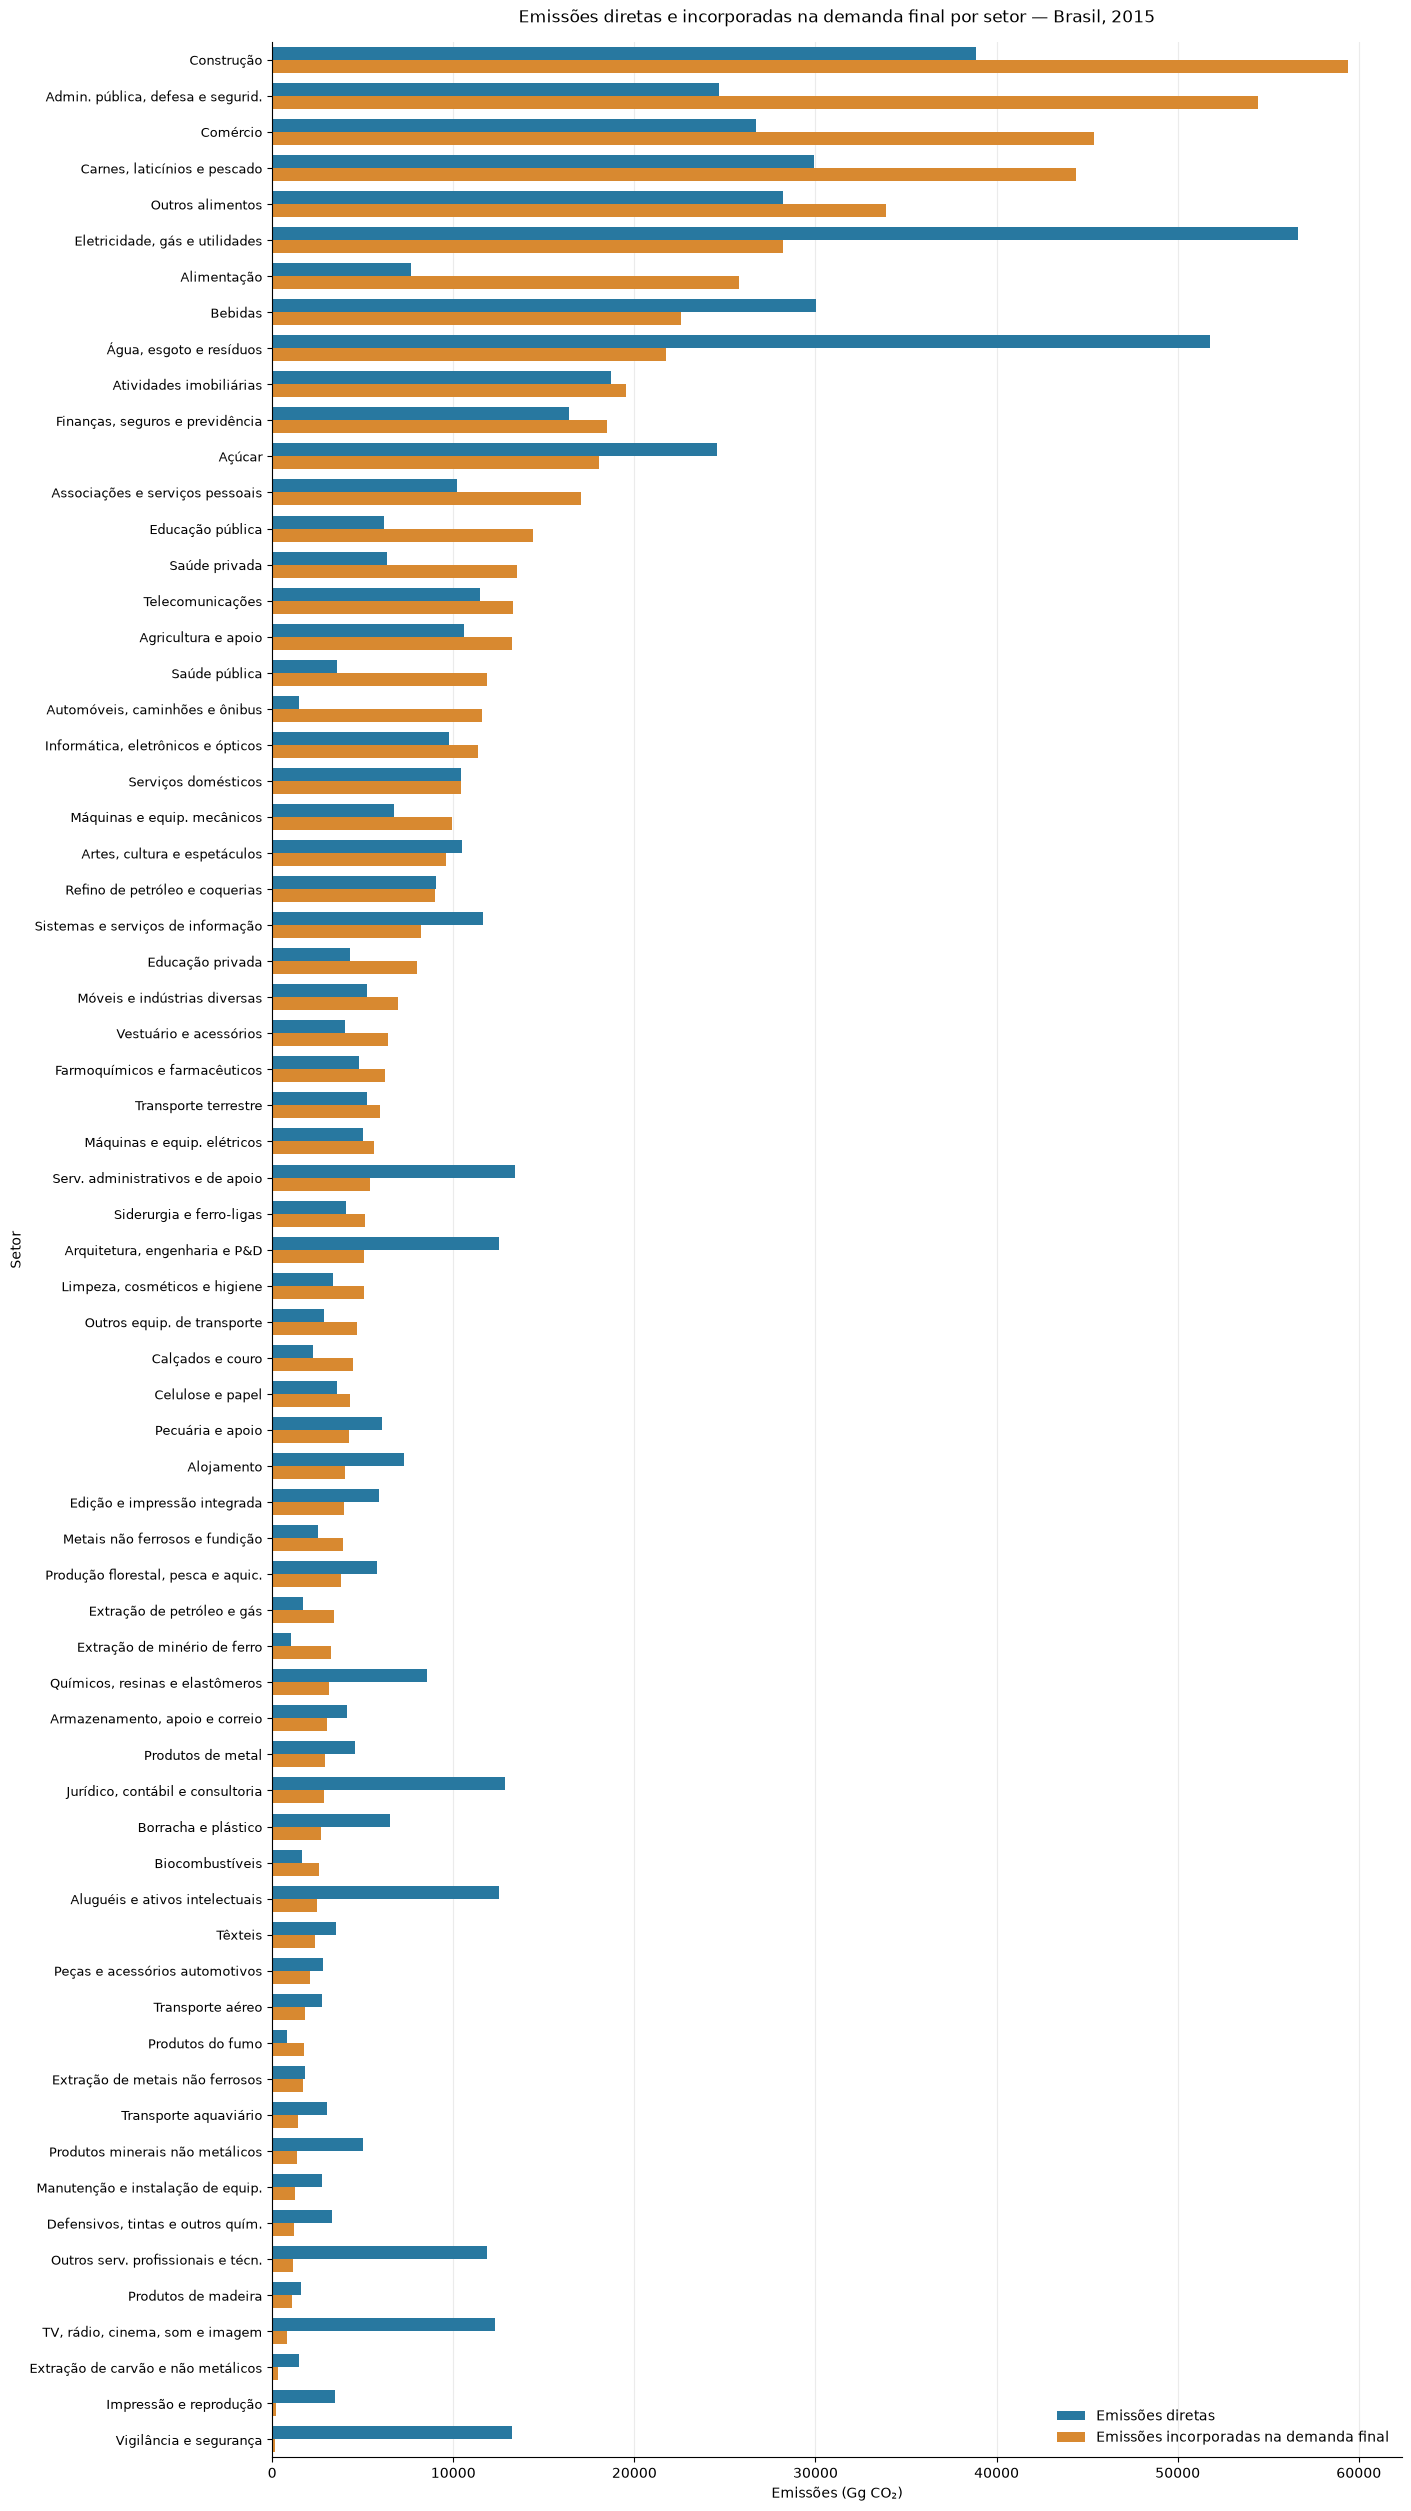

In [7]:
import matplotlib.pyplot as plt
from redes.visualizacoes import ROTULOS_ATIVIDADES_IBGE

emissoes_demanda_final = F.sum(axis=0)

# Com x = Ly, a soma de cada linha de F recupera as emissões diretas.
np.testing.assert_allclose(F.sum(axis=1), c, rtol=1e-8, atol=1e-6)
np.testing.assert_allclose(emissoes_demanda_final.sum(), c.sum(), rtol=1e-8, atol=1e-6)

comparacao_emissoes = pd.DataFrame({
    "Emissões diretas": c,
    "Emissões incorporadas na demanda final": emissoes_demanda_final,
}).sort_values("Emissões incorporadas na demanda final", ascending=False)

rotulos_setores = [ROTULOS_ATIVIDADES_IBGE[str(codigo)] for codigo in comparacao_emissoes.index]
posicoes = np.arange(len(comparacao_emissoes))
altura_barra = 0.36

fig, ax = plt.subplots(figsize=(14, 25), layout="constrained")
ax.barh(
    posicoes - altura_barra / 2,
    comparacao_emissoes["Emissões diretas"],
    height=altura_barra, color="#2878A0", label="Emissões diretas",
)
ax.barh(
    posicoes + altura_barra / 2,
    comparacao_emissoes["Emissões incorporadas na demanda final"],
    height=altura_barra, color="#D88930", label="Emissões incorporadas na demanda final",
)
ax.set_yticks(posicoes, labels=rotulos_setores, fontsize=9)
ax.invert_yaxis()
ax.set_ylim(len(comparacao_emissoes) - 0.5, -0.5)
ax.set_xlabel("Emissões (Gg CO₂)")
ax.set_ylabel("Setor")
ax.set_title("Emissões diretas e incorporadas na demanda final por setor — Brasil, 2015", pad=14)
ax.ticklabel_format(axis="x", style="plain")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
plt.show()


## 8. Economia ilustrativa de quatro setores calibrada à MIP

Objetivo: ilustrar a atribuição das emissões com Eletricidade (3500), Agricultura (0191), Alimentos (1093, Outros produtos alimentares) e Restaurantes (5600, Alimentação). Os rótulos simplificam atividades oficiais. As transações são ilustrativas calibradas, não fluxos brasileiros observados.

Preservamos a proporção **diagonal / produção** em Eletricidade, Agricultura e Alimentos. Por simplificação explícita do exemplo, fixamos a diagonal de Restaurantes em zero (a proporção original é aproximadamente 0,0115%). Preservamos também as proporções da produção bruta entre setores e as intensidades ambientais da seção 7. Uma constante fixa a maior produção em R$ 100 milhões. A divisão entre demanda final e vendas intermediárias e as razões ambientais $u_i/c_i$ são critérios de aproximação, auditados abaixo.

**Estrutura fixa:** Eletricidade fornece a Agricultura, Alimentos e Restaurantes; Agricultura fornece a Alimentos e Restaurantes; Alimentos fornece a Restaurantes. Os quatro atendem à demanda final. Nenhuma relação de retorno é admitida. A diagonal continua na conta e não é desenhada.

A calibração ajusta somente as seis transações entre atividades permitidas, em frações da produção do fornecedor. A demanda final é o saldo de vendas: $y=x-Z\mathbf1$. Restringimos vendas finais e entradas primárias a valores não negativos. $A=Z\operatorname{diag}(x)^{-1}$ e $F=\operatorname{diag}(\varphi)(I-A)^{-1}\operatorname{diag}(y)$ são recalculadas para cada candidato; não aplicamos correções às emissões.

O objetivo combina: média do erro logarítmico quadrático nas razões $u/c$; média do desvio quadrático de $y/x$ em relação à MIP; e uma penalidade pequena de afastamento das transações originais por unidade de produção. Os pesos são explícitos. O ajuste não é único nem prova validade empírica; serve à exposição do conceito.

A ausência de vendas intermediárias de Restaurantes torna impossível preservar sua divisão original de vendas: a demanda final recebe toda a produção, pois sua diagonal foi fixada em zero. A diferença é uma hipótese do exemplo e aparece na tabela de desvios. Os demais critérios também são apresentados antes da figura. As duas contas conservam exatamente o mesmo total e usam uma escala única de cores.


In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from redes import dados,modelo,mip

tabelas_calibracao=dados.carregar_matriz_67("mip_ibge_2015_67")
Z_67=modelo.calcular_matriz_transacoes_intersetoriais_67(tabelas_calibracao)
x_67=modelo.calcular_producao_bruta_67(tabelas_calibracao)
y_67=mip.carregar_demanda_final_nacional_67(tabelas_calibracao)
L_67=mip.carregar_inversa_leontief_ibge_67(tabelas_calibracao)
coef_inicio=dados.carregar_coeficientes_co2("sanguinet_azzoni_2011")[2011]
coef_fim=dados.carregar_coeficientes_co2("sanguinet_azzoni_2018")[2018]
assert coef_inicio.index.equals(coef_fim.index) and len(coef_inicio)==len(x_67)==67
# S1–S67 seguem a ordem das atividades da MIP; a conversão é posicional.
phi_67=pd.Series((coef_inicio+4/7*(coef_fim-coef_inicio)).to_numpy(),index=x_67.index)
F_67=L_67.mul(phi_67,axis=0).mul(y_67,axis=1)
c_67=phi_67*x_67
u_67=F_67.sum(axis=0)
np.testing.assert_allclose(F_67.sum(axis=1),c_67,rtol=1e-8,atol=1e-6)

codigos_calibracao=["3500","0191","1093","5600"]
setores_calibracao=["Eletricidade","Agricultura","Alimentos","Restaurantes"]
escala_calibracao=100/x_67.loc[codigos_calibracao].max()
x_calibrada=x_67.loc[codigos_calibracao].to_numpy()*escala_calibracao
y_calibrada=y_67.loc[codigos_calibracao].to_numpy()*escala_calibracao
diagonal_calibrada=np.diag(Z_67.loc[codigos_calibracao,codigos_calibracao])*escala_calibracao
# Simplificação solicitada para a economia ilustrativa; a MIP original não é alterada.
indice_restaurantes=setores_calibracao.index("Restaurantes")
diagonal_calibrada[indice_restaurantes]=0.0
phi_calibrada=phi_67.loc[codigos_calibracao].to_numpy()
c_calibrada=phi_calibrada*x_calibrada
razao_alvo=u_67.loc[codigos_calibracao].to_numpy()/c_67.loc[codigos_calibracao].to_numpy()
# Estrutura original do desenho: só estes seis fluxos entre atividades são permitidos.
indices_relacoes=[(0,1),(0,2),(0,3),(1,2),(1,3),(2,3)]
relacoes_calibracao=[(setores_calibracao[i],setores_calibracao[j]) for i,j in indices_relacoes]
fracao_demanda_alvo=y_calibrada/x_calibrada
# Referência explícita: valor observado da ligação / produção do fornecedor.
transacoes_referencia=np.array([
    Z_67.loc[codigos_calibracao[i],codigos_calibracao[j]]/x_67.loc[codigos_calibracao[i]]
    for i,j in indices_relacoes
])
peso_demanda=1.0
peso_transacoes=0.001


SHA-256 verificado: Matriz_de_Insumo_Produto_2015_Nivel_67.xls.original
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2011.csv
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2018.csv


### 8.1. Calibração com estrutura fixa e auditoria dos desvios

As seis variáveis $v_{ij}=Z_{ij}/x_i$ determinam as ligações permitidas. A diagonal é fixada antes do ajuste e a demanda final é calculada por fechamento das linhas. O objetivo é

$$\operatorname{média}\{\log[(u_i/c_i)/(u_i^{BR}/c_i^{BR})]^2\}
+\lambda_y\operatorname{média}\{(y_i/x_i-y_i^{BR}/x_i^{BR})^2\}
+\lambda_Z\operatorname{média}\{(v_{ij}-v_{ij}^{BR})^2\},$$

com $\lambda_y=1$ e $\lambda_Z=0{,}001$. O algoritmo começa nas frações monetárias originais do subbloco e não usa aleatoriedade. Conferimos convergência e restrições; isso não demonstra ótimo global ou unicidade. A diferença na fração de demanda final é apresentada em **pontos percentuais**; o erro de $u/c$ é **percentual relativo**.


In [2]:
def contas_calibradas(fracoes_transacoes):
    """Calcula as duas contas para os seis fluxos permitidos e a diagonal fixa."""
    Z_teste=np.diag(diagonal_calibrada)
    for fracao,(i,j) in zip(fracoes_transacoes,indices_relacoes):
        Z_teste[i,j]=fracao*x_calibrada[i]
    y_teste=x_calibrada-Z_teste.sum(axis=1)
    A_teste=Z_teste/x_calibrada[None,:]
    L_teste=np.linalg.inv(np.eye(4)-A_teste)
    F_teste=phi_calibrada[:,None]*L_teste*y_teste[None,:]
    return Z_teste,y_teste,F_teste

def erro_calibracao(fracoes_transacoes):
    _,y_teste,F_teste=contas_calibradas(fracoes_transacoes)
    # Candidatos fora da região econômica não têm razão ambiental válida.
    if (y_teste<=0).any():
        return 1e6+np.minimum(y_teste,0).dot(np.minimum(y_teste,0))
    razao_teste=F_teste.sum(axis=0)/c_calibrada
    return (np.mean(np.log(razao_teste/razao_alvo)**2)
        +peso_demanda*np.mean((y_teste/x_calibrada-fracao_demanda_alvo)**2)
        +peso_transacoes*np.mean((fracoes_transacoes-transacoes_referencia)**2))

restricoes_calibracao=[
    {"type":"ineq","fun":lambda v:contas_calibradas(v)[1]},
    {"type":"ineq","fun":lambda v:x_calibrada-contas_calibradas(v)[0].sum(axis=0)},
]
resultado_calibracao=minimize(erro_calibracao,transacoes_referencia,method="SLSQP",bounds=[(0,1)]*6,
    constraints=restricoes_calibracao,options={"ftol":1e-13,"maxiter":1000})
assert resultado_calibracao.success,resultado_calibracao.message
Z_calibrada,y_calibrada,F_calibrada=contas_calibradas(resultado_calibracao.x)
A_calibrada=Z_calibrada/x_calibrada[None,:]
u_calibrada=F_calibrada.sum(axis=0)

for i in range(4):
    for j in range(4):
        if i!=j and (i,j) not in indices_relacoes:
            assert Z_calibrada[i,j]==0
assert (y_calibrada>=0).all()
assert (x_calibrada-Z_calibrada.sum(axis=0)>=-1e-9).all()
np.testing.assert_allclose(Z_calibrada.sum(axis=1)+y_calibrada,x_calibrada,rtol=1e-12)
# Somente Restaurantes tem diagonal suprimida por hipótese do exemplo.
mascara_diagonal=np.arange(4)!=indice_restaurantes
np.testing.assert_allclose((np.diag(Z_calibrada)/x_calibrada)[mascara_diagonal],
    (np.diag(Z_67.loc[codigos_calibracao,codigos_calibracao])/x_67.loc[codigos_calibracao].to_numpy())[mascara_diagonal],rtol=1e-12)
assert Z_calibrada[indice_restaurantes,indice_restaurantes]==0.0
np.testing.assert_allclose(y_calibrada[indice_restaurantes],x_calibrada[indice_restaurantes],rtol=1e-12)
assert max(abs(np.linalg.eigvals(A_calibrada)))<1
np.testing.assert_allclose(F_calibrada.sum(axis=1),c_calibrada,rtol=1e-10)
np.testing.assert_allclose(c_calibrada.sum(),u_calibrada.sum(),rtol=1e-10)
F_verificada=np.column_stack([phi_calibrada*np.linalg.solve(np.eye(4)-A_calibrada,np.eye(4)[:,j]*y_calibrada[j]) for j in range(4)])
np.testing.assert_allclose(F_verificada,F_calibrada,rtol=1e-12)
np.testing.assert_allclose(10*Z_calibrada.sum(axis=1)+10*y_calibrada,10*x_calibrada,rtol=1e-12)

auditoria_calibracao=pd.DataFrame({
    "Diagonal / produção — MIP":np.diag(Z_67.loc[codigos_calibracao,codigos_calibracao])/x_67.loc[codigos_calibracao].to_numpy(),
    "Diagonal / produção — exemplo":np.diag(Z_calibrada)/x_calibrada,
    "Demanda final / produção — MIP":fracao_demanda_alvo,
    "Demanda final / produção — exemplo":y_calibrada/x_calibrada,
    "Diferença da fração de demanda final (p.p.)":100*(y_calibrada/x_calibrada-fracao_demanda_alvo),
    "Emissões demanda / produção — MIP":razao_alvo,
    "Emissões demanda / produção — exemplo":u_calibrada/c_calibrada,
    "Erro relativo da razão ambiental (%)":100*((u_calibrada/c_calibrada)/razao_alvo-1),
},index=setores_calibracao)
display(auditoria_calibracao)
display(pd.DataFrame(Z_calibrada,index=setores_calibracao,columns=setores_calibracao))
display(pd.DataFrame({"Produção (Gg CO₂)":c_calibrada,"Demanda (Gg CO₂)":u_calibrada},index=setores_calibracao))
print("Totais das duas contas:",c_calibrada.sum(),u_calibrada.sum(),"Gg CO₂")
print("Maior erro relativo da razão ambiental:",auditoria_calibracao.iloc[:,-1].abs().max(),"%")


Totais das duas contas: 33.3340052015905 33.3340052015905 Gg CO₂
Maior erro relativo da razão ambiental: 2.8637559788941447 %


              Diagonal / produção — MIP  ...  Erro relativo da razão ambiental (%)
Eletricidade                   0.331152  ...                              0.992510
Agricultura                    0.021056  ...                              1.092095
Alimentos                      0.091899  ...                              2.863756
Restaurantes                   0.000115  ...                              2.161299

[4 rows x 8 columns]

              Eletricidade  Agricultura  Alimentos  Restaurantes
Eletricidade     27.917384    13.736853  11.440410      2.819897
Agricultura       0.000000     2.105648  31.874668     12.238292
Alimentos         0.000000     0.000000   7.523864     19.985977
Restaurantes      0.000000     0.000000   0.000000      0.000000

              Produção (Gg CO₂)  Demanda (Gg CO₂)
Eletricidade          18.306003          9.216675
Agricultura            3.428571          4.333671
Alimentos              9.122775         11.264102
Restaurantes           2.476655          8.519557

### 8.2. Figura com as seis relações originais e quatro entregas finais

A área representa a produção setorial; em Demanda Final, o valor total recebido. As espessuras representam transações monetárias, sem piso. A escala de cores é linear e comum aos oito valores. Só as cores mudam entre os quadros.

Todas as seis relações permitidas são desenhadas, junto às quatro entregas à demanda final. Não existem relações de retorno na matriz calibrada. Apenas os laços da diagonal são omitidos visualmente, mantendo seus valores nas contas e nas áreas.


As áreas dos cinco círculos usam uma escala visual comum ampliada para acomodar os rótulos, sem alterar suas proporções. O nome Alimentos é preto no quadro da demanda; as cores de preenchimento continuam determinadas pelos valores calculados.

Os quadros (a) e (b) são construídos abaixo. O Sankey (c) e a legenda comum são acrescentados na seção 9.1, onde a figura completa é exibida e exportada.

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

Z_figura=pd.DataFrame(Z_calibrada,index=setores_calibracao,columns=setores_calibracao)
fluxos_figura=Z_figura.copy()
fluxos_figura["Demanda final"]=y_calibrada
valores_nos=dict(zip(setores_calibracao,x_calibrada))
valores_nos["Demanda final"]=y_calibrada.sum()
rede=nx.DiGraph()
for no,valor in valores_nos.items():rede.add_node(no,valor=valor)
for origem in setores_calibracao:
    for destino in fluxos_figura.columns:
        valor=fluxos_figura.loc[origem,destino]
        if origem!=destino and valor>1e-10:rede.add_edge(origem,destino,weight=valor)
posicoes={"Eletricidade":(0,2.3),"Agricultura":(0,-2.3),"Alimentos":(4.1,-2.3),"Restaurantes":(4.1,2.3),"Demanda final":(8.2,0)}
rotulos={no:no for no in rede};rotulos["Demanda final"]="Demanda\nFinal"
curvaturas={("Eletricidade","Demanda final"):-0.9,("Agricultura","Demanda final"):0.9}
# Identificadores ligam os setores emissores e os produtos finais ao Sankey.
romanos_origem=dict(zip(setores_calibracao,["I","II","III","IV"]))
romanos_destino=dict(zip(setores_calibracao,["V","VI","VII","VIII"]))
deslocamentos_romanos={"Eletricidade":(8,6),"Agricultura":(8,-6),
                       "Alimentos":(0,-28),"Restaurantes":(0,28)}
nos=list(rede);areas=np.array([valores_nos[no]*85 for no in nos])
escala_setas=5/fluxos_figura.to_numpy().max()
paleta=plt.get_cmap("viridis_r")
valores_cor=np.r_[c_calibrada,u_calibrada]
norma=Normalize(vmin=valores_cor.min(),vmax=valores_cor.max())
# Uma figura: redes acima, Sankey abaixo, com escala de cores única.
fig_calibrada=plt.figure(figsize=(11.2,11.0))
eixos_calibrados=[fig_calibrada.add_axes([0.015,0.565,0.46,0.415]),
                  fig_calibrada.add_axes([0.525,0.565,0.46,0.415])]
for ax,titulo,conta in zip(eixos_calibrados,["Lado da Produção","Lado da Demanda"],[c_calibrada,u_calibrada]):
    ax.set(xlim=(-1.7,10.7),ylim=(-5.6,5.6),aspect="equal")
    ax.set_title(("(a) " if titulo=="Lado da Produção" else "(b) ")+titulo,fontfamily="DejaVu Serif",fontsize=13,pad=12)
    for origem,destino,d in rede.edges(data=True):
        rad=curvaturas.get((origem,destino),0)
        setas=nx.draw_networkx_edges(rede,posicoes,ax=ax,edgelist=[(origem,destino)],nodelist=nos,node_size=areas,
            width=d["weight"]*escala_setas,edge_color="black",arrows=True,arrowstyle="-|>",arrowsize=12,
            connectionstyle=f"arc3,rad={rad}",min_source_margin=3,min_target_margin=3)
        for seta in setas:seta.set_capstyle("butt");seta.set_joinstyle("miter")
        if titulo=="Lado da Demanda" and destino=="Demanda final":
            # Ponto próximo à chegada, na curva quadrática da própria seta.
            p0,p1,p2=setas[0].get_path().vertices[:3]
            t_rotulo=0.88
            ponto_rotulo=(1-t_rotulo)**2*p0+2*t_rotulo*(1-t_rotulo)*p1+t_rotulo**2*p2
            dx,dy=deslocamentos_romanos[origem]
            ax.annotate(romanos_destino[origem],xy=ponto_rotulo,xytext=(dx,dy),
                textcoords="offset points",ha="left" if dx else "center",
                va="bottom" if dy>0 else "top",fontfamily="DejaVu Serif",fontsize=10.5,
                bbox={"facecolor":"white","edgecolor":"none","pad":0.3},zorder=5)
    cores={no:paleta(norma(conta[i])) for i,no in enumerate(setores_calibracao)}
    cores["Demanda final"]=(1,1,1,1)
    nx.draw_networkx_nodes(rede,posicoes,ax=ax,nodelist=nos,node_size=areas,node_color=[cores[no] for no in nos],edgecolors="black",linewidths=0.8)
    for no in nos:
        r,g,b,_=cores[no];luminancia=0.2126*r+0.7152*g+0.0722*b
        rotulo_no=(romanos_origem[no]+"\n"+rotulos[no]
                   if titulo=="Lado da Produção" and no in romanos_origem else rotulos[no])
        nx.draw_networkx_labels(rede,posicoes,labels={no:rotulo_no},ax=ax,font_size=10.5,font_family="DejaVu Serif",
            font_color="black" if (no=="Alimentos" and titulo=="Lado da Demanda") else ("white" if luminancia<0.45 else "black"))
    ax.axis("off")
pasta_calibracao=Path("outputs/economia_calibrada_v4");pasta_calibracao.mkdir(parents=True,exist_ok=True)
fluxos_figura.to_csv(pasta_calibracao/"fluxos_calibrados.csv")
pd.DataFrame(F_calibrada,index=setores_calibracao,columns=setores_calibracao).to_csv(pasta_calibracao/"atribuicao_F.csv")
auditoria_calibracao.to_csv(pasta_calibracao/"comparacao_ratios.csv")
pd.DataFrame({"producao_r_milhoes":x_calibrada,"demanda_final_r_milhoes":y_calibrada,"phi_gg_por_r_milhao":phi_calibrada,"emissoes_producao_gg":c_calibrada,"emissoes_demanda_gg":u_calibrada},index=setores_calibracao).to_csv(pasta_calibracao/"contas_calibradas.csv")
# Evita exibir a figura incompleta; o quadro (c) é acrescentado na seção 9.1.
plt.close(fig_calibrada)


## 9. Valores da economia e atribuição das emissões

As tabelas usam os mesmos valores dos dois quadros, sem novo ajuste. Na tabela monetária, as linhas identificam fornecedores e as colunas os setores usuários; a demanda final inclui exportações. A última coluna é a produção bruta, $x_i=\sum_j Z_{ij}+y_i$, **não** o valor adicionado. Trata-se do bloco de transações e demanda final da economia ilustrativa calibrada, não da MIP brasileira observada.

A tabela ambiental compara $c_i=\varphi_i x_i$ e $u_j=\sum_i F_{ij}$ em Gg de CO₂. Totais são calculados antes do arredondamento; os CSV preservam a precisão dos cálculos. As tabelas LaTeX são exportadas para a mesma pasta das figuras.

A célula Restaurantes–Restaurantes é zero por hipótese explícita na seção 8; não é apenas arredondada na tabela. Mantida a produção setorial, o fechamento destina toda a produção de Restaurantes à demanda final. A calibração e a matriz ambiental $F$ são recalculadas com essa hipótese.

As tabelas e a matriz $F$ com totais permanecem como apoio à auditoria no notebook. A figura exportada apresenta somente as duas redes e o Sankey.


In [4]:
tabela_emissoes = pd.DataFrame({
    "Produção": c_calibrada,
    "Demanda": u_calibrada,
}, index=setores_calibracao)
tabela_emissoes.index.name = "Setor"
tabela_emissoes.loc["Total"] = tabela_emissoes.sum(axis=0)

tabela_mip = fluxos_figura.copy()
tabela_mip["Produção total"] = x_calibrada
tabela_mip.index.name = "Fornecedor"
np.testing.assert_allclose(
    tabela_mip.drop(columns="Produção total").sum(axis=1),
    tabela_mip["Produção total"], rtol=1e-12,
)
np.testing.assert_allclose(tabela_emissoes.loc["Total", "Produção"],
                           tabela_emissoes.loc["Total", "Demanda"], rtol=1e-12)
display(tabela_emissoes.round(2))
display(tabela_mip.round(2))

# Arredondamento somente na apresentação; as matrizes continuam com precisão completa.
formato_decimal = lambda valor: f"{valor:.2f}".replace(".", ",")
# Tabulares simples, sem dependência adicional de um motor de templates.
linhas_tex = [r"\begin{tabular}{@{}lrr@{}}", r"\toprule",
              r"Setor & Produção & Demanda \\", r"\midrule"]
for setor,linha in tabela_emissoes.iterrows():
    if setor=="Total": linhas_tex.append(r"\midrule")
    linhas_tex.append(setor+" & "+" & ".join(formato_decimal(v) for v in linha)+r" \\")
linhas_tex += [r"\bottomrule", r"\end{tabular}"]
(pasta_calibracao/"tabela_emissoes.tex").write_text("\n".join(linhas_tex),encoding="utf-8")
linhas_tex = [r"\begin{tabular}{@{}lrrrrrr@{}}", r"\toprule",
    r"Fornecedor & Eletricidade & Agricultura & Alimentos & Restaurantes & \shortstack{Demanda\\final} & \shortstack{Produção\\total} \\",
    r"\midrule"]
for setor,linha in tabela_mip.iterrows():
    linhas_tex.append(setor+" & "+" & ".join(formato_decimal(v) for v in linha)+r" \\")
linhas_tex += [r"\bottomrule", r"\end{tabular}"]
(pasta_calibracao/"tabela_mip.tex").write_text("\n".join(linhas_tex),encoding="utf-8")
tabela_emissoes.to_csv(pasta_calibracao/"tabela_emissoes.csv")
tabela_mip.to_csv(pasta_calibracao/"tabela_mip.csv")

# Os nomes identificam as atividades; os códigos romanos serão anexados aos totais na figura.
F_tabela = pd.DataFrame(F_calibrada,index=setores_calibracao,columns=setores_calibracao)
matriz_F_exibicao = F_tabela.copy()
matriz_F_exibicao["Total produção"] = c_calibrada
matriz_F_exibicao.loc["Total demanda"] = np.r_[u_calibrada,c_calibrada.sum()]
np.testing.assert_allclose(F_tabela.sum(axis=1),c_calibrada,rtol=1e-10)
np.testing.assert_allclose(F_tabela.sum(axis=0),u_calibrada,rtol=1e-10)
display(matriz_F_exibicao.round(2))
matriz_F_exibicao.to_csv(pasta_calibracao/"matriz_F_com_totais.csv")


,Produção,Demanda
Setor,,
Eletricidade,18.31,9.22
Agricultura,3.43,4.33
Alimentos,9.12,11.26
Restaurantes,2.48,8.52
Total,33.33,33.33


,Eletricidade,Agricultura,Alimentos,Restaurantes,Demanda final,Produção total
Fornecedor,,,,,,
Eletricidade,27.92,13.74,11.44,2.82,28.39,84.30
Agricultura,0.00,2.11,31.87,12.24,53.78,100.00
Alimentos,0.00,0.00,7.52,19.99,54.36,81.87
Restaurantes,0.00,0.00,0.00,0.00,72.24,72.24


,Eletricidade,Agricultura,Alimentos,Restaurantes,Total produção
Eletricidade,9.22,2.45,3.78,2.86,18.31
Agricultura,0.00,1.88,0.82,0.73,3.43
Alimentos,0.00,0.00,6.67,2.45,9.12
Restaurantes,0.00,0.00,0.00,2.48,2.48
Total demanda,9.22,4.33,11.26,8.52,33.33


### 9.1. Sankey da atribuição pelo lado da demanda

O Sankey representa a matriz $F$, não a matriz monetária $Z$. À esquerda estão os setores emissores, com totais $c_i$; à direita, os produtos destinados à demanda final, com totais $u_j$. Cada faixa tem espessura proporcional a $F_{ij}$, em Gg de CO₂, com **uma única escala linear**, sem piso. As duas margens totalizam as mesmas emissões.

As cores das barras seguem a escala comum dos dois quadros anteriores; as faixas seguem a cor do setor de origem. As ligações de um setor para seu próprio produto são mantidas: $F_{ii}$ contabiliza emissões originadas no setor $i$ e atribuídas ao produto final desse mesmo setor, considerando os encadeamentos do sistema. Essa diagonal ambiental não se confunde com a diagonal monetária $Z_{ii}$. As faixas expressam atribuição contábil de emissões já ocorridas, não transporte físico de CO₂.

A geometria é construída com curvas de Bézier no Matplotlib para exportação vetorial. As alturas das barras e os intervalos das faixas são calculados diretamente de $F$, e seus fechamentos são verificados abaixo.

O Sankey integra a mesma figura das duas redes, com uma única barra de cores. Os três quadros usam o mesmo objeto `norma`, definido pelos oito valores de emissões setoriais das duas contas. As barras do Sankey recebem exatamente as mesmas cores dos círculos correspondentes; suas faixas herdam a cor da origem, com transparência para evidenciar cruzamentos.

**Correspondências visuais:** I–IV identificam os setores emissores nos círculos do quadro (a) e na margem esquerda do Sankey. V–VIII identificam os produtos finais na margem direita do Sankey e junto à chegada das respectivas setas à Demanda Final no quadro (b). Os códigos identificam setores/produtos; não alteram as grandezas representadas por setas e faixas.

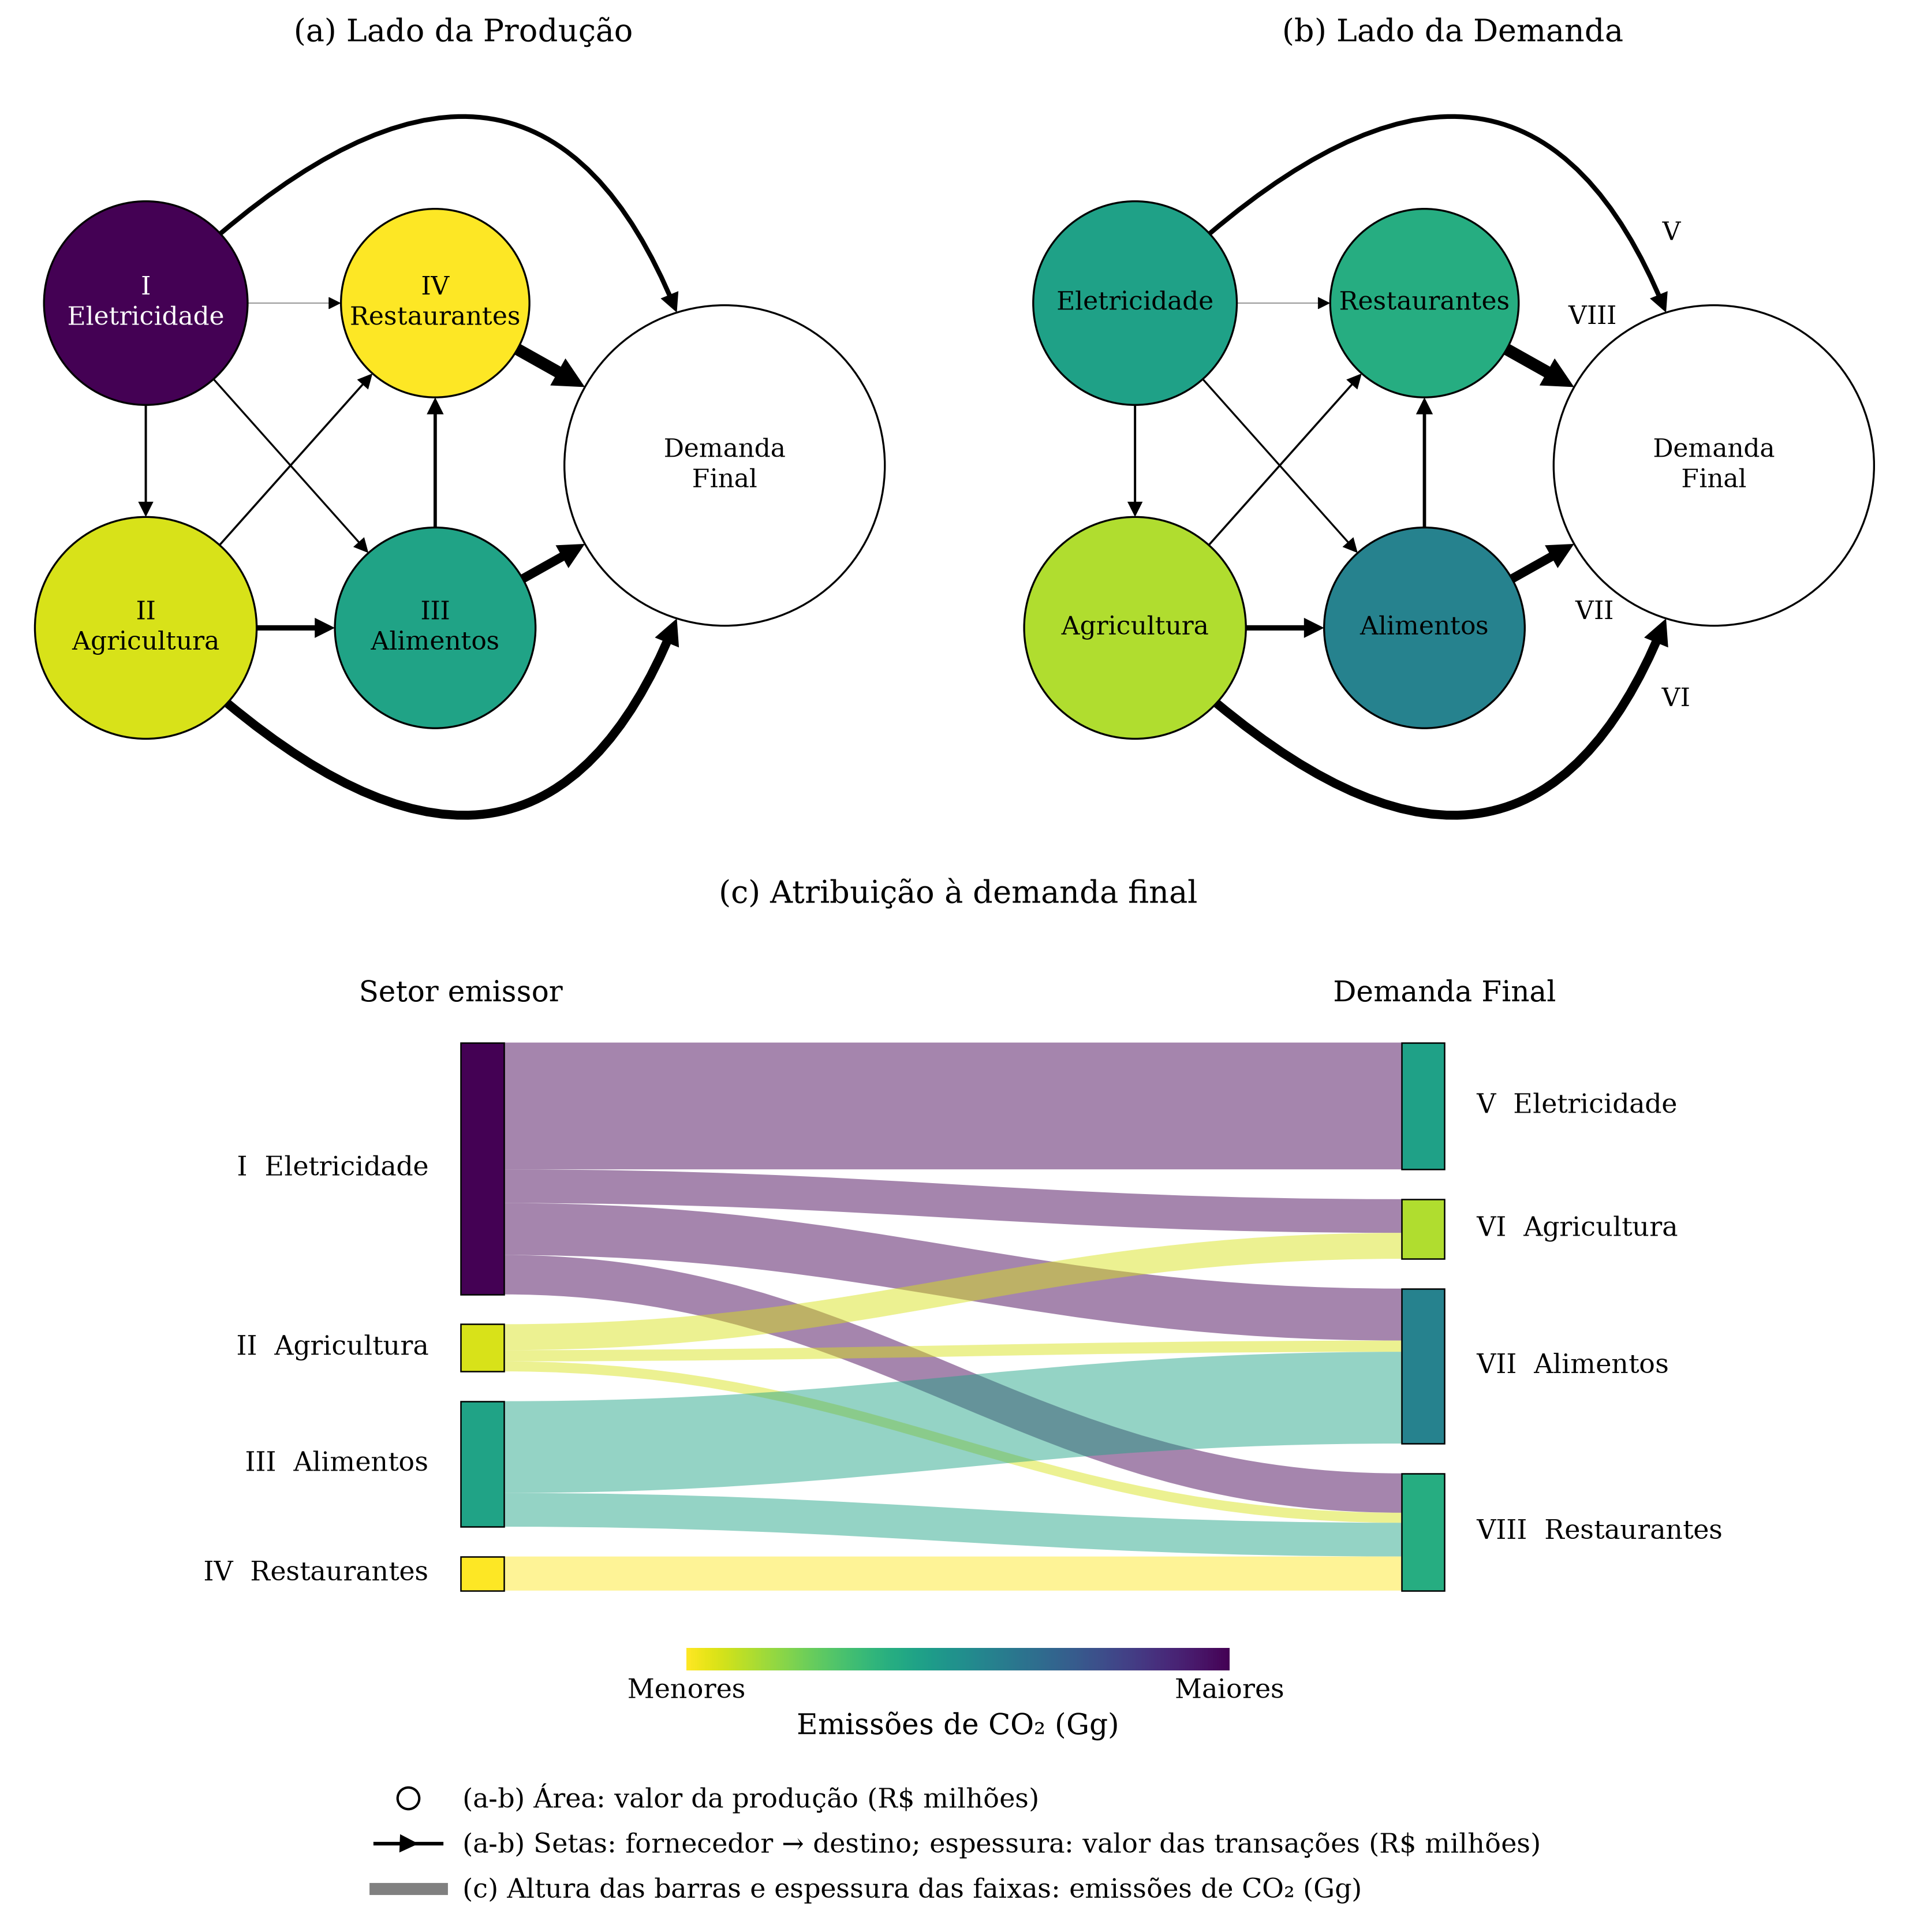

In [5]:
from matplotlib.path import Path as Caminho
from matplotlib.patches import PathPatch, Rectangle

np.testing.assert_allclose(F_calibrada.sum(axis=1), c_calibrada, rtol=1e-10)
np.testing.assert_allclose(F_calibrada.sum(axis=0), u_calibrada, rtol=1e-10)
assert (F_calibrada >= 0).all()

# A mesma unidade de altura em ambas as margens e em todas as faixas.
escala_sankey = 1/F_calibrada.sum()
alturas_origem = c_calibrada*escala_sankey
alturas_destino = u_calibrada*escala_sankey
intervalo_barras = 0.065
altura_total = 1 + 3*intervalo_barras
topos_origem = altura_total - np.r_[0, np.cumsum(alturas_origem[:-1])+intervalo_barras*np.arange(1,4)]
topos_destino = altura_total - np.r_[0, np.cumsum(alturas_destino[:-1])+intervalo_barras*np.arange(1,4)]
cursor_origem = topos_origem.copy()
cursor_destino = topos_destino.copy()
x_esquerda, x_direita, largura_barra = 0, 3.5, 0.16
x_inicio, x_fim = x_esquerda+largura_barra, x_direita
x_controle_1 = x_inicio + 0.42*(x_fim-x_inicio)
x_controle_2 = x_fim - 0.42*(x_fim-x_inicio)
ax_sankey = fig_calibrada.add_axes([0.015,0.17,0.97,0.355])

for i in range(4):
    for j in range(4):
        valor = F_calibrada[i,j]
        if valor == 0:
            continue
        altura = valor*escala_sankey
        origem_topo, destino_topo = cursor_origem[i], cursor_destino[j]
        origem_base, destino_base = origem_topo-altura, destino_topo-altura
        vertices = [
            (x_inicio,origem_topo), (x_controle_1,origem_topo),
            (x_controle_2,destino_topo), (x_fim,destino_topo),
            (x_fim,destino_base), (x_controle_2,destino_base),
            (x_controle_1,origem_base), (x_inicio,origem_base),
            (x_inicio,origem_topo),
        ]
        codigos = [Caminho.MOVETO, Caminho.CURVE4, Caminho.CURVE4, Caminho.CURVE4,
                   Caminho.LINETO, Caminho.CURVE4, Caminho.CURVE4, Caminho.CURVE4,
                   Caminho.CLOSEPOLY]
        faixa = PathPatch(Caminho(vertices,codigos), facecolor=paleta(norma(c_calibrada[i])),
                          alpha=0.48, edgecolor="none", zorder=1)
        ax_sankey.add_patch(faixa)
        cursor_origem[i] -= altura
        cursor_destino[j] -= altura

# Confere o fechamento geométrico de todas as barras, incluindo ligações F_ii.
np.testing.assert_allclose(cursor_origem, topos_origem-alturas_origem, atol=1e-12)
np.testing.assert_allclose(cursor_destino, topos_destino-alturas_destino, atol=1e-12)
for valores,alturas,topos,x_barra,lado in [
    (c_calibrada,alturas_origem,topos_origem,x_esquerda,"origem"),
    (u_calibrada,alturas_destino,topos_destino,x_direita,"destino"),
]:
    for i,nome in enumerate(setores_calibracao):
        ax_sankey.add_patch(Rectangle((x_barra,topos[i]-alturas[i]),largura_barra,alturas[i],
            facecolor=paleta(norma(valores[i])),edgecolor="black",linewidth=0.6,zorder=2))
        ax_sankey.text(x_barra-0.12 if lado=="origem" else x_barra+largura_barra+0.12,
            topos[i]-alturas[i]/2,(romanos_origem[nome] if lado=="origem" else romanos_destino[nome])+"  "+nome,
            ha="right" if lado=="origem" else "left",
            va="center",fontfamily="DejaVu Serif",fontsize=11)
ax_sankey.text(x_esquerda,altura_total+0.09,"Setor emissor",ha="center",
    fontfamily="DejaVu Serif",fontsize=12)
ax_sankey.text(x_direita+largura_barra,altura_total+0.09,"Demanda Final",ha="center",
    fontfamily="DejaVu Serif",fontsize=12,linespacing=1.3)
ax_sankey.set(xlim=(-1.65,5.35),ylim=(-0.05,altura_total+0.23))
ax_sankey.axis("off")
fig_calibrada.text(0.5,0.543,"(c) Atribuição à demanda final",
    ha="center",fontfamily="DejaVu Serif",fontsize=13)

# A mesma instância de Normalize e a mesma paleta governam os quadros coloridos.
ax_cor_comum=fig_calibrada.add_axes([0.36,0.14,0.28,0.012])
barra_comum=fig_calibrada.colorbar(ScalarMappable(norm=norma,cmap=paleta),
    cax=ax_cor_comum,orientation="horizontal",ticks=[norma.vmin,norma.vmax])
barra_comum.ax.set_xticklabels(["Menores","Maiores"],fontfamily="DejaVu Serif",fontsize=11)
barra_comum.ax.tick_params(length=0,pad=3)
barra_comum.set_label("Emissões de CO₂ (Gg)",fontfamily="DejaVu Serif",fontsize=12,labelpad=3)
barra_comum.outline.set_visible(False)
legenda_comum=[
    Line2D([],[],marker="o",linestyle="none",markersize=9,markerfacecolor="white",markeredgecolor="black",
        label="(a-b) Área: valor da produção (R$ milhões)"),
    Line2D([],[],color="black",linewidth=1.5,marker=">",markevery=[1],
        label="(a-b) Setas: fornecedor → destino; espessura: valor das transações (R$ milhões)"),
    Line2D([],[],color="gray",linewidth=5,
        label="(c) Altura das barras e espessura das faixas: emissões de CO₂ (Gg)"),
]
fig_calibrada.legend(handles=legenda_comum,loc="lower center",frameon=False,
    prop={"family":"DejaVu Serif","size":11},handlelength=2.5,labelspacing=0.7,
    bbox_to_anchor=(0.5,0.005))
assert len(fig_calibrada.axes)==4  # duas redes, Sankey e barra de cores
for extensao in ["pdf","svg","png"]:
    fig_calibrada.savefig(pasta_calibracao/f"contabilidade_com_sankey.{extensao}",
        dpi=300,bbox_inches="tight")
display(fig_calibrada)
